In [66]:
import pandas as pd
import numpy as np
import sklearn as sk
import matplotlib.pyplot as plt
import seaborn as sns
import streamlit as st
import joblib


In [95]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["area", "bhk", "bathroom", "age"]
categorical_features = ["status", "location", "builder"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Log-transform target
'''y = np.log1p(df1["price"])
X = df1.drop("price", axis=1)'''

'y = np.log1p(df1["price"])\nX = df1.drop("price", axis=1)'

# MODEL BUILDING

In [97]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", LinearRegression())
])

# Split data
X1 = df1.drop("price", axis=1)
Y1 = df1["price"]

# MODEL TRAINING

In [98]:
from sklearn.model_selection import train_test_split
X1_train, X1_test, Y1_train, Y1_test = train_test_split(X1, Y1, test_size=0.2, random_state=42)

model.fit(X1_train, Y1_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](7,)","['area','status','bhk',...,'age','location','builder']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,7
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated

# MODEL EVALUTION

In [103]:
from sklearn.metrics import mean_squared_error, r2_score

Y1_pred_test = model.predict(X1_test)
Y1_pred_train = model.predict(X1_train)

mse = mean_squared_error(Y1_test, Y1_pred_test)
rmse = np.sqrt(mse)
r2_test = r2_score(Y1_test, Y1_pred_test)
r2_train = r2_score(Y1_train, Y1_pred_train)
print("MSE:", mse)
print("RMSE:", rmse)
print("R^2 Test:", r2_test)
print("R^2 Train", r2_train)

MSE: 745.412663779232
RMSE: 27.302246496931932
R^2 Test: 0.9440450104485264
R^2 Train 0.9465957193601734


# MODEL PREDICTION

In [104]:
new_house = pd.DataFrame({
    "area": [1200],
    "bhk": [2],
    "bathroom": [2],
    "age": [5],
    "status": ["ready"],
    "location": ["Chennai"],
    "builder": ["ABC"]
})

prediction = model.predict(new_house)

price_lakh = prediction[0]
if price_lakh < 1:
    print(f"Predicted Price: ₹{price_lakh * 100000:,.0f}")
elif price_lakh < 100:
    print(f"Predicted Price: ₹{price_lakh:,.2f} lakh")
elif price_lakh < 100000:
    print(f"Predicted Price: ₹{price_lakh / 100:,.2f} crore")
else:
    print(f"Predicted Price: ₹{price_lakh / 100000:,.2f} thousand crore")


Predicted Price: ₹1.12 crore


# VISUALIZATION

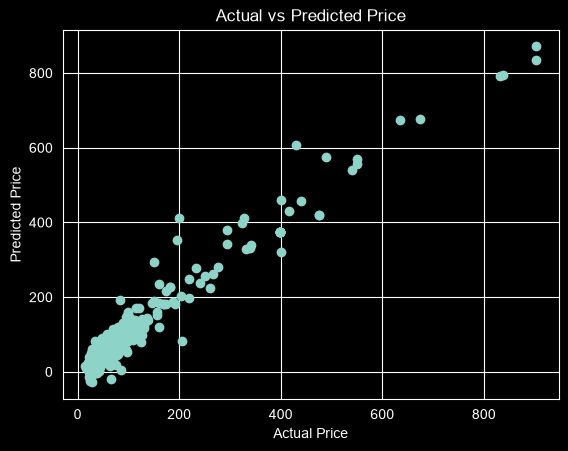

In [106]:
plt.scatter(Y1_test, Y1_pred_test)
plt.xlabel("Actual Price")
plt.ylabel("Predicted Price")
plt.title("Actual vs Predicted Price")
plt.show()

# MODEL SAVING

In [102]:

joblib.dump(model, "house_price_linearmodel1.pkl")

['house_price_linearmodel1.pkl']

## Final Report
The Linear Regression model achieved an MSE of 745.41 and an RMSE of 27.30 on the test set. The model obtained an R² score of 0.9440 on the testing data and 0.9466 on the training data, indicating that approximately 94% of the variance in house prices is explained by the selected features. The small difference between training and testing R² scores demonstrates good generalization capability and minimal overfitting, making the model reliable for house price prediction.

# Lasso Regression

In [50]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = ["area", "bhk", "bathroom", "age"]
categorical_features = ["status", "location", "builder"]

preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_features),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical_features)
    ]
)

# Log-transform target
y = np.log1p(df1["price"])
X = df1.drop("price", axis=1)

In [53]:
# MODEL BUILDING
from sklearn.pipeline import Pipeline
from sklearn.linear_model import Lasso
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

pipeline = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("regressor", Lasso())
])

param_grid = {
    'regressor__alpha': np.logspace(-3, 0, 10)
}

grid_search = GridSearchCV(
    estimator=pipeline,
    param_grid=param_grid,
    cv=5,
    scoring='neg_mean_squared_error'
)

grid_search.fit(X_train, y_train)

model2 = grid_search.best_estimator_




In [56]:
from sklearn.metrics import mean_squared_error, r2_score

y_pred = model2.predict(X_test)

rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print("RMSE:", rmse)

train_pred = model2.predict(X_train)
test_pred = model2.predict(X_test)

print("Train R²:", r2_score(y_train, train_pred))
print("Test  R²:", r2_score(y_test, test_pred))

RMSE: 0.21629168264285206
Train R²: 0.8813531953599827
Test  R²: 0.8242132233270906


In [58]:
new_house = pd.DataFrame({
    "area": [1200],
    "bhk": [2],
    "bathroom": [2],
    "age": [5],
    "status": ["ready"],
    "location": ["Chennai"],
    "builder": ["ABC"]
})

prediction = model.predict(new_house)

price_lakh = prediction[0]
if price_lakh < 1:
    print(f"Predicted Price: ₹{price_lakh * 100000:,.0f}")
elif price_lakh < 100:
    print(f"Predicted Price: ₹{price_lakh:,.2f} lakh")
elif price_lakh < 100000:
    print(f"Predicted Price: ₹{price_lakh / 100:,.2f} crore")
else:
    print(f"Predicted Price: ₹{price_lakh / 100000:,.2f} thousand crore")


Predicted Price: ₹66.47 lakh


In [60]:
joblib.dump(model, "house_price_Lassomodel.pkl")

['house_price_Lassomodel.pkl']

In [62]:
best_lasso = model2.named_steps['regressor']

print(best_lasso.coef_)

[ 3.01141540e-01  7.95592910e-02  3.04616634e-02  2.22883303e-02
 -1.83121534e-02  0.00000000e+00  5.72843464e-02  0.00000000e+00
 -0.00000000e+00  0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00  0.00000000e+00 -0.00000000e+00  0.00000000e+00
  0.00000000e+00 -0.00000000e+00 -0.00000000e+00  0.00000000e+00
  0.00000000e+00  0.00000000e+00 -1.44134488e-04  2.21866851e-01
 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00  0.00000000e+00
 -1.07867825e-03  0.00000000e+00  0.00000000e+00 -0.00000000e+00
  0.00000000e+00 -2.89869648e-01 -0.00000000e+00  5.67815013e-02
 -1.92740938e-01 -0.00000000e+00  0.00000000e+00 -1.34697146e-01
  0.00000000e+00  0.00000000e+00  1.00490810e-01  0.00000000e+00
 -0.00000000e+00 -0.00000000e+00  0.00000000e+00  0.00000000e+00
  1.82525010e-01 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00  0.00000000e+00 -0.00000000e+00  0.00000000e+00
  1.69888304e-01 -0.00000000e+00 -0.00000000e+00 -0.00000000e+00
 -0.00000000e+00  0.00000

In [63]:
feature_names = model2.named_steps[
    'preprocessor'
].get_feature_names_out()

coef_df = pd.DataFrame({
    'feature': feature_names,
    'coef': best_lasso.coef_
})

coef_df = coef_df.sort_values(
    by='coef',
    key=abs,
    ascending=False
)

print(coef_df.head(20))

                                         feature      coef
144                    cat__location_Veppampattu -0.444170
97                       cat__location_Perungudi  0.389090
161                 cat__builder_Baashyaam Group -0.368664
157  cat__builder_Amarprakash Developers Pvt Ltd -0.313775
0                                      num__area  0.301142
33            cat__location_Kanathur Reddikuppam -0.289870
135                    cat__location_Vadanemmeli  0.257604
126                  cat__location_Thirumazhisai -0.247485
127               cat__location_Thirumullaivoyal -0.236008
155                   cat__builder_Advaita Homes -0.232985
99                           cat__location_Porur  0.232843
23                   cat__location_East Tambaram  0.221867
87                      cat__location_Pallavaram  0.206718
36                  cat__location_Kattankulathur -0.192741
171                   cat__builder_DAC Promoters  0.189654
48                       cat__location_Koyambedu  0.1825

In [65]:
(coef_df['coef'] == 0).sum()

,feature,coef,abs_coef
144,cat__location_Veppampattu,-0.444170,0.444170
97,cat__location_Perungudi,0.389090,0.389090
161,cat__builder_Baashyaam Group,-0.368664,0.368664
157,cat__builder_Amarprakash Developers Pvt Ltd,-0.313775,0.313775
0,num__area,0.301142,0.301142
33,cat__location_Kanathur Reddikuppam,-0.289870,0.289870
135,cat__location_Vadanemmeli,0.257604,0.257604
126,cat__location_Thirumazhisai,-0.247485,0.247485
127,cat__location_Thirumullaivoyal,-0.236008,0.236008
155,cat__builder_Advaita Homes,-0.232985,0.232985


# Regressor Model 2